**AR(1) inflation forecast baseline**


AR means **autoregressive**: the variable uses its own past value. The number 1 means that we use one previous month.

$$Inflation_t = c + \phi Inflation_{t-1} + error_t$$

- $Inflation_t$: inflation we want to forecast;
- $Inflation_{t-1}$: inflation observed one month earlier;
- $c$: the constant or starting level;
- $\phi$: how strongly last month's inflation carries into this month.

In [1]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

# The test period starts here. All earlier observations form the training period.
TEST_START = '2017-01-01'

# Database settings are loaded from the project-root .env file.

In [2]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Locate the repository whether Jupyter starts at the root or notebook folder.
search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
sys.path.insert(0, str(PROJECT_ROOT))
from modelling.config import get_sqlalchemy_engine
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'
RESULTS_DIR = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
AR1_FORECAST_PATH = RESULTS_DIR / 'ar1_forecasts.csv'
AR1_METRICS_PATH = RESULTS_DIR / 'ar1_metrics.json'

print('Selected source:', DATA_SOURCE)

Selected source: database


In [3]:
if DATA_SOURCE == 'database':
    from sqlalchemy import create_engine, text

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={'month_date': 'Date', 'cpi_value': 'CPI'})
else:
    raw = pd.read_csv(CSV_PATH, usecols=['Date', 'CPIAUCSL'], parse_dates=['Date'])
    raw = raw.rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw['CPI'] = pd.to_numeric(raw['CPI'], errors='coerce')
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())
raw.head()

Rows: 204
Period: 2007-01-01 to 2023-12-01


,CPI
Date,
2007-01-01,203.437
2007-02-01,204.226
2007-03-01,205.288
2007-04-01,205.904
2007-05-01,206.755


In [4]:
# Compute month-over-month inflation and its lagged value. Inflation_Lag1 is the previouse month's inflation rate
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100
data['Inflation_Lag1'] = data['Inflation_MoM'].shift(1)

model_data = data[['Inflation_MoM', 'Inflation_Lag1']].dropna().copy()
model_data.head(6)

,Inflation_MoM,Inflation_Lag1
Date,,
2007-03-01,0.520012,0.387835
2007-04-01,0.300066,0.520012
2007-05-01,0.413299,0.300066
2007-06-01,0.231675,0.413299
2007-07-01,0.178060,0.231675
2007-08-01,0.030828,0.178060


**Seprate test and Train dataset**

In [5]:
test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('The selected TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Fit the AR(1) equation**

In [6]:
X_train = sm.add_constant(train[['Inflation_Lag1']], has_constant='add')
# Learn the constant and coefficient with OLS regression.
ar1_model = sm.OLS(train['Inflation_MoM'], X_train).fit()

constant = ar1_model.params['const']
phi = ar1_model.params['Inflation_Lag1']

print(f'Estimated equation: Inflation_t = {constant:.4f} + {phi:.4f} × Inflation_(t-1)')
pd.DataFrame({
    'Estimate': [constant, phi],
    'Plain-language meaning': [
        'Starting level when previous inflation is zero',
        'How much of last month carries into this month',
    ],
}, index=['Constant (c)', 'Lag effect (phi)'])

Estimated equation: Inflation_t = 0.0694 + 0.5228 × Inflation_(t-1)


,Estimate,Plain-language meaning
Constant (c),0.069392,Starting level when previous inflation is zero
Lag effect (phi),0.522808,How much of last month carries into this month


**Make one-month-ahead forecasts**

In [7]:
X_test = sm.add_constant(test[['Inflation_Lag1']], has_constant='add')
test['Forecast_AR1'] = ar1_model.predict(X_test)

test[['Inflation_Lag1', 'Inflation_MoM', 'Forecast_AR1']].head(10)

,Inflation_Lag1,Inflation_MoM,Forecast_AR1
Date,,,
2017-01-01,0.252452,0.404308,0.201376
2017-02-01,0.404308,0.159266,0.280768
2017-03-01,0.159266,-0.046720,0.152658
2017-04-01,-0.046720,0.123415,0.044967
2017-05-01,0.123415,-0.077398,0.133915
2017-06-01,-0.077398,0.065163,0.028928
2017-07-01,0.065163,0.032765,0.103460
2017-08-01,0.032765,0.384863,0.086522
2017-09-01,0.384863,0.510639,0.270602


**Evaluate and save the AR(1) results**

In [8]:
forecast_errors = test['Inflation_MoM'] - test['Forecast_AR1']
rmse = np.sqrt(np.mean(forecast_errors ** 2))
mae = np.mean(np.abs(forecast_errors))
mean_error = np.mean(forecast_errors)

metric_table = pd.DataFrame({
    'RMSE': [rmse],
    'MAE': [mae],
    'Mean Error (Actual - Forecast)': [mean_error],
}, index=['AR(1)'])

forecast_output = pd.DataFrame({
    'Date': test.index,
    'Actual': test['Inflation_MoM'].to_numpy(),
    'Forecast': test['Forecast_AR1'].to_numpy(),
    'Error': forecast_errors.to_numpy(),
})
forecast_output.to_csv(AR1_FORECAST_PATH, index=False)

metrics_output = {
    'model': 'AR(1)',
    'data_source': DATA_SOURCE,
    'target': 'Inflation_MoM',
    'forecast_horizon_months': 1,
    'train_start': str(train.index.min().date()),
    'train_end': str(train.index.max().date()),
    'test_start': str(test.index.min().date()),
    'test_end': str(test.index.max().date()),
    'n_train': int(len(train)),
    'n_test': int(len(test)),
    'parameters': {
        'constant': float(constant),
        'inflation_lag1': float(phi),
    },
    'metrics': {
        'rmse': float(rmse),
        'mae': float(mae),
        'mean_error_actual_minus_forecast': float(mean_error),
    },
}
with AR1_METRICS_PATH.open('w', encoding='utf-8') as file:
    json.dump(metrics_output, file, indent=2)

print('Saved forecasts:', AR1_FORECAST_PATH)
print('Saved metrics:  ', AR1_METRICS_PATH)
metric_table

Saved forecasts: d:\Master Semester 4\Thesis\data\processed\model_results\ar1_forecasts.csv
Saved metrics:   d:\Master Semester 4\Thesis\data\processed\model_results\ar1_metrics.json


,RMSE,MAE,Mean Error (Actual - Forecast)
AR(1),0.265153,0.195604,0.067525


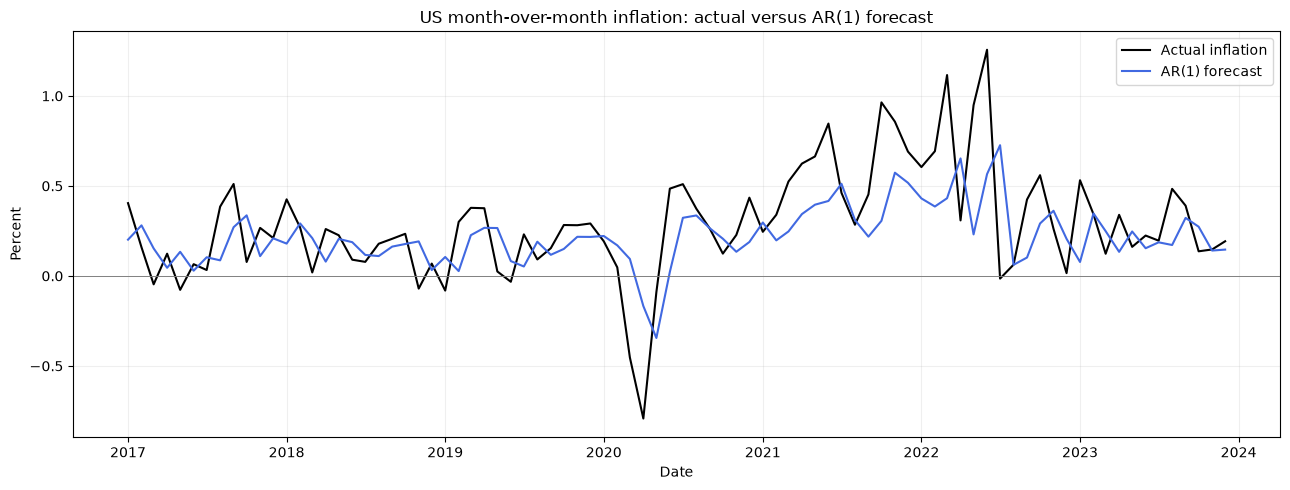

In [9]:
plt.figure(figsize=(13, 5))
plt.plot(test.index, test['Inflation_MoM'], label='Actual inflation', color='black')
plt.plot(test.index, test['Forecast_AR1'], label='AR(1) forecast', color='royalblue')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US month-over-month inflation: actual versus AR(1) forecast')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()